# Análise Exploratória — Risco de Lesão (Série A 2022–2025)

Entregável de **Ciência de Dados**. Usamos o `dataset_modelo.csv` (partida × jogador na BRA1) e os CSVs auxiliares de lesões/elenco.

Roteiro:
1. **Panorama da base** (este bloco)
2. Perfil das lesões
3. Calendário e congestionamento
4. Auditoria do alvo e deriva de registro
5. Carga × lesão
6. Comparativos entre clubes e posições

## 1. Panorama da base

Objetivo: entender **tamanho**, **qualidade** e **desbalanceamento** antes de qualquer gráfico mais fino.

O que entra aqui:
- volumes (linhas, jogadores, clubes, período)
- nulos nas features
- distribuição do alvo `y` (lesão nos próximos 14 dias)
- taxa de `y=1` por ano — e o salto em 2024–25 ligado ao registro no Transfermarkt

### 1.1 Leitura

Carregamos as três fontes e medimos o tamanho da base.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROC = Path("../data/processed")
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

ds = pd.read_csv(PROC / "dataset_modelo.csv", parse_dates=["data"])
# amostra principal: exclui lesão com início no próprio dia da partida (ver tópico 4.2)
ds = ds.loc[ds["lesao_no_dia"].eq(0)].reset_index(drop=True)
inj = pd.read_csv(PROC / "injuries_clean.csv", parse_dates=["data_inicio", "data_fim"])
squad = pd.read_csv(PROC / "squad_raw.csv")

print("dataset_modelo:", f"{len(ds):,} linhas |", ds.player_id.nunique(), "jogadores |", ds.clube_id.nunique(), "clubes")
print("período:", ds.data.min().date(), "→", ds.data.max().date())
print("injuries_clean:", f"{len(inj):,} episódios |", inj.player_id.nunique(), "jogadores com histórico")
print("squad_raw:", f"{len(squad):,} linhas |", squad.player_id.nunique(), "jogadores únicos")
print("clubes por temporada:", squad.groupby("temporada")["clube_id"].nunique().to_dict())

dataset_modelo: 47,704 linhas | 1579 jogadores | 28 clubes
período: 2022-04-09 → 2025-12-07
injuries_clean: 6,253 episódios | 1278 jogadores com histórico
squad_raw: 4,476 linhas | 2347 jogadores únicos
clubes por temporada: {2022: 20, 2023: 20, 2024: 20, 2025: 20}


**Leitura:** cada linha do `dataset_modelo` é uma partida da Série A em que o jogador entrou em campo: ~47,7 mil linhas de 1.579 jogadores, 20 clubes por temporada (28 distintos em 2022–2025). Os 2.347 jogadores do `squad_raw` incluem reservas que nunca entraram em campo na liga.

### 1.2 Qualidade

Nulos e resumo das features numéricas.


In [2]:
# Qualidade: nulos e resumo das features numéricas
nulos = (ds.isna().mean() * 100).sort_values(ascending=False)
print("Nulos (%):")
print(nulos[nulos > 0].round(2).to_string())

cols = [
    "minutos_jogados", "minutos_7d", "minutos_cronica_4sem", "acwr",
    "dias_desde_ultima_partida", "jogos_30d", "idade", "n_lesoes_previas",
]
ds[cols].describe().round(2)

Nulos (%):
dias_desde_ultima_lesao      39.20
jogos_desde_retorno          39.20
dias_desde_retorno           39.20
categoria_ultima_lesao       39.20
dias_fora_ultima_lesao       39.20
acwr_desacoplada              9.33
acwr                          6.01
dias_desde_ultima_partida     0.03
acwr_ewma                     0.03


,minutos_jogados,minutos_7d,minutos_cronica_4sem,acwr,dias_desde_ultima_partida,jogos_30d,idade,n_lesoes_previas
count,47704.00,47704.00,47704.00,44835.00,47690.00,47704.00,47704.00,47704.00
mean,62.76,43.62,59.84,0.80,10.41,3.98,27.29,2.45
std,30.87,46.94,40.38,0.95,25.79,2.01,4.86,4.05
min,1.00,0.00,0.00,0.00,1.00,0.00,16.00,0.00
25%,32.00,0.00,24.50,0.00,3.00,3.00,24.00,0.00
50%,76.00,25.00,59.25,0.67,5.00,4.00,27.00,1.00
75%,90.00,90.00,90.00,1.14,8.00,5.00,31.00,3.00
max,90.00,180.00,180.00,4.00,1302.00,9.00,45.00,39.00


**Leitura:** `dias_desde_ultima_lesao` nulo (~39%) = sem lesão anterior registrada. `acwr` nulo (~6%) = sem carga crônica nas 4 semanas anteriores (a versão desacoplada, ~9%, perde também quem só jogou na última semana). Valores extremos (ACWR alto, muitos dias sem jogar) são retorno de lesão/pouca história — não removemos aqui.

### 1.3 Desbalanceamento

Distribuição do alvo `y` (lesão nos próximos 14 dias).


y
y=0 (sem lesão em 14d)    45337
y=1 (lesão em 14d)         2367

Taxa positiva: 4.96%


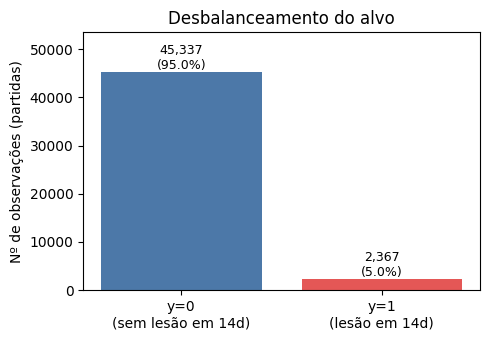

In [3]:
# Desbalanceamento do alvo
counts = ds["y"].value_counts().sort_index()
print(counts.rename({0: "y=0 (sem lesão em 14d)", 1: "y=1 (lesão em 14d)"}).to_string())
print(f"\nTaxa positiva: {100 * ds.y.mean():.2f}%")

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(
    ["y=0\n(sem lesão em 14d)", "y=1\n(lesão em 14d)"],
    counts.values,
    color=["#4C78A8", "#E45756"],
)
ax.set_ylabel("Nº de observações (partidas)")
ax.set_title("Desbalanceamento do alvo")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({100 * v / len(ds):.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, counts.max() * 1.18)
fig.tight_layout()
fig.savefig(FIG / "01_desbalanceamento_alvo.png", dpi=120)
plt.show()

**Leitura:** só ~5% das partidas são seguidas de lesão em 14 dias. Um modelo que sempre chuta `y=0` acertaria ~95% — por isso, na Fase 5, priorizamos AUC-PR e métricas top-k, não acurácia.

### 1.4 O salto de 2024–25

Taxa de `y=1` por ano e volume de lesões registradas no Transfermarkt.


Por ano no dataset_modelo:


,obs,jogadores,y1,taxa_%
ano,,,,
2022,11929,748,308,2.58
2023,11926,739,233,1.95
2024,11928,709,828,6.94
2025,11921,736,998,8.37



Episódios de lesão-alvo com início em cada ano (injuries_clean):
ano_inicio
2019     303
2020     296
2021     343
2022     433
2023     516
2024     912
2025    1040
2026     681


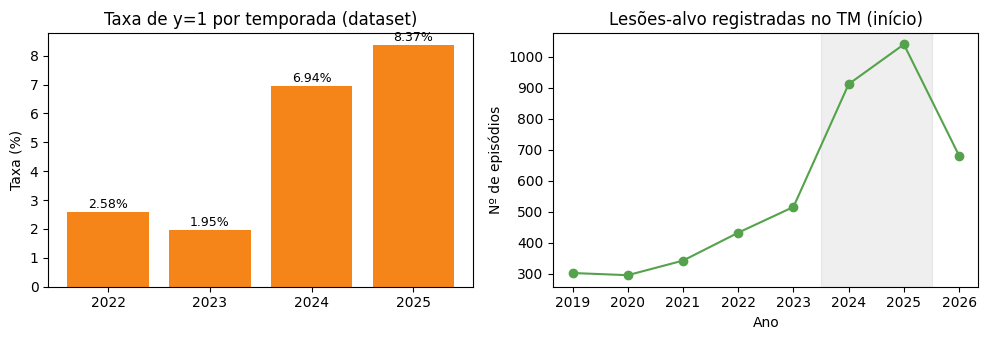

In [4]:
# Taxa de y=1 por ano + volume de lesões registradas no TM
ano = ds.groupby("ano").agg(obs=("y", "size"), jogadores=("player_id", "nunique"), y1=("y", "sum"))
ano["taxa_%"] = (100 * ano.y1 / ano.obs).round(2)
print("Por ano no dataset_modelo:")
display(ano)

alvo = inj.loc[inj["conta_como_alvo"]].copy()
alvo["ano_inicio"] = alvo["data_inicio"].dt.year
serie = alvo.groupby("ano_inicio").size().loc[2019:2026]
print("\nEpisódios de lesão-alvo com início em cada ano (injuries_clean):")
print(serie.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].bar(ano.index.astype(str), ano["taxa_%"], color="#F58518")
axes[0].set_title("Taxa de y=1 por temporada (dataset)")
axes[0].set_ylabel("Taxa (%)")
for x, v in zip(ano.index.astype(str), ano["taxa_%"]):
    axes[0].text(x, v + 0.15, f"{v:.2f}%", ha="center", fontsize=9)

axes[1].plot(serie.index, serie.values, marker="o", color="#54A24B")
axes[1].axvspan(2023.5, 2025.5, color="gray", alpha=0.12)  # anos de registro mais completo
axes[1].set_title("Lesões-alvo registradas no TM (início)")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Nº de episódios")

fig.tight_layout()
fig.savefig(FIG / "01_taxa_e_registro_por_ano.png", dpi=120)
plt.show()

**Leitura:** o volume de partidas é estável (~12 mil/ano), mas a taxa de `y=1` muda de patamar: 2,0–2,6% em 2022–23 e 6,9–8,4% em 2024–25. Os episódios registrados no TM dobram no mesmo período (433–516 → 912–1.040 por ano) → mais registro na fonte, não necessariamente “epidemia” (investigado no tópico 4). Qualquer comparação entre anos precisa levar isso em conta.

---
**Fim do tópico 1.**

## 2. Perfil das lesões

Objetivo: descrever **onde**, **em quem** e **por quanto tempo** as lesões aparecem — usando `injuries_clean` (episódios) e o `dataset_modelo` (taxa por partida, que já controla exposição).

Recorte principal: lesões com `conta_como_alvo=True` e início entre **2022 e 2025** (excluídas doença, COVID, gestão de esforço, etc.).

### 2.1 Onde se lesionam (anatomia)

Lesões-alvo com início em 2022–2025, por categoria anatômica.


Lesões-alvo no período 2022–2025: 2,901
Excluídas como não-traumáticas (toda a base): 598


,n,%
categoria_lesao,,
coxa,684,23.6
outras,532,18.3
joelho,458,15.8
muscular_geral,447,15.4
tornozelo,244,8.4
adutores,123,4.2
panturrilha,122,4.2
pe,63,2.2
perna,49,1.7


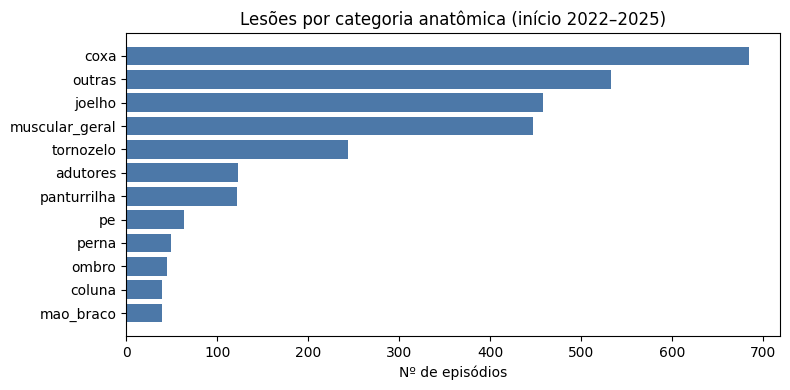

In [5]:
import sys
sys.path.append("../scripts")
from features import MAPA_POSICAO as MAPA  # mesmo mapa usado no pipeline

les = inj.loc[inj["conta_como_alvo"]].copy()
les_p = les.loc[les["data_inicio"].between("2022-01-01", "2025-12-31")].copy()
print(f"Lesões-alvo no período 2022–2025: {len(les_p):,}")
print(f"Excluídas como não-traumáticas (toda a base): {(inj.categoria_lesao == 'nao_traumatica').sum()}")

cat = les_p["categoria_lesao"].value_counts()
display(pd.DataFrame({"n": cat, "%": (100 * cat / len(les_p)).round(1)}))

fig, ax = plt.subplots(figsize=(8, 4))
top = cat.head(12).sort_values()
ax.barh(top.index, top.values, color="#4C78A8")
ax.set_xlabel("Nº de episódios")
ax.set_title("Lesões por categoria anatômica (início 2022–2025)")
fig.tight_layout()
fig.savefig(FIG / "02_categorias_anatomicas.png", dpi=120)
plt.show()


**Leitura:** dominam membros inferiores — coxa ~24%, joelho ~16%, muscular geral ~15%, tornozelo ~8%. `outras` (~18%) concentra textos vagos do Transfermarkt (“desconhecida”, “problemas físicos”), mais comuns nos anos antigos.

### 2.2 Por posição

Taxa por partida e prevalência no elenco.


,partidas,lesoes_14d,taxa_%
posicao_grupo,,,
zagueiro,7161,402,5.61
atacante,6128,327,5.34
ponta,8341,435,5.22
meia,9044,456,5.04
lateral,7875,384,4.88
volante,6089,281,4.61
goleiro,3066,82,2.67


Prevalência (% jogadores do elenco com ≥1 lesão 2022–25):


,n_jogadores,com_lesao,prev_%
posicao_grupo,,,
ponta,400,195,48.8
atacante,297,142,47.8
zagueiro,394,183,46.4
volante,266,123,46.2
lateral,362,159,43.9
meia,416,181,43.5
goleiro,212,59,27.8


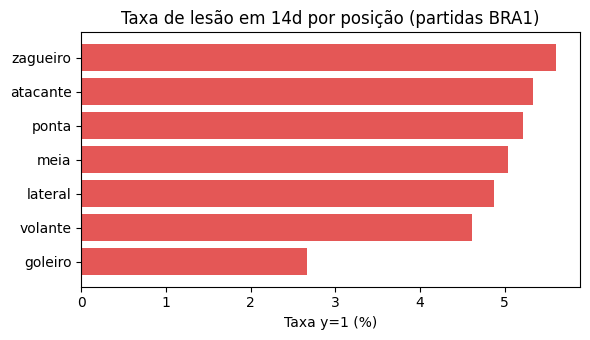

In [6]:
# Taxa de y=1 por posição (controla exposição: partidas jogadas)
taxa_pos = (
    ds.groupby("posicao_grupo")
    .agg(partidas=("y", "size"), lesoes_14d=("y", "sum"))
    .assign(**{"taxa_%": lambda d: (100 * d.lesoes_14d / d.partidas).round(2)})
    .sort_values("taxa_%", ascending=False)
)
display(taxa_pos)

# Prevalência: % dos jogadores do elenco 2022–25 com ≥1 lesão-alvo no período
pos_map = squad.copy()
pos_map["player_id"] = pos_map["player_id"].astype(str)
pos_map["posicao_grupo"] = pos_map["posicao"].map(MAPA).fillna("outras")
jog = (
    pos_map.loc[pos_map["temporada"].between(2022, 2025)]
    .groupby("player_id", as_index=False)
    .agg(posicao_grupo=("posicao_grupo", lambda x: x.mode().iloc[0]))
)
com_lesao = set(les_p["player_id"].astype(str))
jog["teve_lesao"] = jog["player_id"].isin(com_lesao)
prev = (
    jog.groupby("posicao_grupo")
    .agg(n_jogadores=("player_id", "size"), com_lesao=("teve_lesao", "sum"))
    .assign(**{"prev_%": lambda d: (100 * d.com_lesao / d.n_jogadores).round(1)})
    .sort_values("prev_%", ascending=False)
)
print("Prevalência (% jogadores do elenco com ≥1 lesão 2022–25):")
display(prev)

fig, ax = plt.subplots(figsize=(6, 3.5))
tp = taxa_pos.sort_values("taxa_%")
ax.barh(tp.index, tp["taxa_%"], color="#E45756")
ax.set_xlabel("Taxa y=1 (%)")
ax.set_title("Taxa de lesão em 14d por posição (partidas BRA1)")
fig.tight_layout()
fig.savefig(FIG / "02_taxa_por_posicao.png", dpi=120)
plt.show()

**Leitura:** goleiros têm taxa bem menor (~2,7% por partida; prevalência ~28% contra 44–49% nos demais). Entre jogadores de linha as diferenças são modestas (4,6% volantes a 5,6% zagueiros). Posição sozinha não explica o risco — fora o goleiro.

### 2.3 Por idade

Taxa de `y=1` por faixa etária (exposição = partidas jogadas).


,partidas,lesoes_14d,taxa_%
faixa_idade,,,
16-20,3683,95,2.58
21-25,14488,652,4.50
26-30,16700,916,5.49
31-35,10588,569,5.37
36+,2245,135,6.01


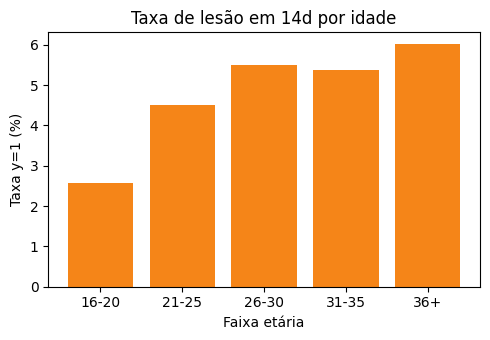

In [7]:
# Idade: taxa de y=1 por faixa (exposição = partidas)
ds["faixa_idade"] = pd.cut(
    ds["idade"], bins=[15, 20, 25, 30, 35, 45],
    labels=["16-20", "21-25", "26-30", "31-35", "36+"],
)
taxa_idade = (
    ds.groupby("faixa_idade", observed=True)
    .agg(partidas=("y", "size"), lesoes_14d=("y", "sum"))
    .assign(**{"taxa_%": lambda d: (100 * d.lesoes_14d / d.partidas).round(2)})
)
display(taxa_idade)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(taxa_idade.index.astype(str), taxa_idade["taxa_%"], color="#F58518")
ax.set_ylabel("Taxa y=1 (%)")
ax.set_xlabel("Faixa etária")
ax.set_title("Taxa de lesão em 14d por idade")
fig.tight_layout()
fig.savefig(FIG / "02_taxa_por_idade.png", dpi=120)
plt.show()

**Leitura:** 16–20 anos com a menor taxa (2,6%); o risco sobe até ~5,5% aos 26–35 e chega a 6,0% aos 36+. Idade se mistura com minutos e histórico prévio (mais velhos acumulam lesões) — a modelagem separa melhor esses efeitos.

### 2.4 Duração e gravidade

Dias parado e jogos perdidos, no geral e por categoria.


Dias parado — resumo (lesões 2022–2025):


,count,mean,std,min,25%,50%,75%,max
dias_parado,2901.0,55.4,90.4,2.0,13.0,26.0,54.0,1690.0


Jogos perdidos:


,count,mean,std,min,25%,50%,75%,max
jogos_perdidos,2832.0,8.5,12.8,1.0,2.0,4.0,9.0,132.0


Mediana de dias parado por categoria:


,mediana_dias
categoria_lesao,
joelho,64.5
mao_braco,38.0
pe,38.0
coluna,31.0
quadril,31.0
coxa,26.0
ombro,25.0
adutores,25.0
panturrilha,23.5


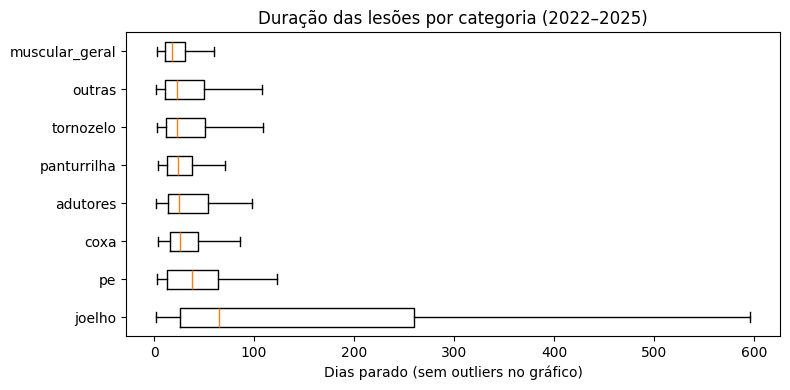

In [8]:
print("Dias parado — resumo (lesões 2022–2025):")
display(les_p["dias_parado"].describe().round(1).to_frame().T)
print("Jogos perdidos:")
display(les_p["jogos_perdidos"].describe().round(1).to_frame().T)

med = les_p.groupby("categoria_lesao")["dias_parado"].median().sort_values(ascending=False)
print("Mediana de dias parado por categoria:")
display(med.head(10).to_frame("mediana_dias"))

tops = cat.head(8).index.tolist()
sub = les_p.loc[les_p["categoria_lesao"].isin(tops)]
order = sub.groupby("categoria_lesao")["dias_parado"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 4))
data = [sub.loc[sub["categoria_lesao"] == c, "dias_parado"].dropna() for c in order]
ax.boxplot(data, tick_labels=list(order), vert=False, showfliers=False)
ax.set_xlabel("Dias parado (sem outliers no gráfico)")
ax.set_title("Duração das lesões por categoria (2022–2025)")
fig.tight_layout()
fig.savefig(FIG / "02_duracao_por_categoria.png", dpi=120)
plt.show()

**Leitura:** mediana de ~26 dias parado (média ~55, puxada por joelho/LCA). Joelho é o mais grave (mediana ~65 dias). O alvo `y` prevê ocorrência em 14 dias, não a severidade.

---
**Fim do tópico 2.** Próximo: calendário e congestionamento.

## 3. Calendário e congestionamento

Objetivo: ver se a taxa de lesão varia ao longo da temporada e se indicadores de densidade de jogos (`jogos_30d`, dias desde a última partida) se associam a `y`.


### 3.1 Evolução temporal da taxa

Taxa de `y=1` por mês no Brasileirão 2022–2025.


,partidas,lesoes_14d,taxa_%
ano_mes,,,
2022-04,1066,7,0.66
2022-05,1411,12,0.85
2022-06,1904,38,2.00
2022-07,1854,30,1.62
2022-08,1290,26,2.02
2022-09,1259,49,3.89
2022-10,1918,109,5.68
2022-11,1227,37,3.02
2023-04,913,44,4.82


Por mês do ano (2022–2025 agregados):


,partidas,lesoes_14d,taxa_%
mes,,,
3,316,30,9.49
4,4741,341,7.19
5,4740,169,3.57
6,5867,275,4.69
7,6665,392,5.88
8,5521,297,5.38
9,4785,268,5.60
10,6403,317,4.95
11,6581,250,3.80


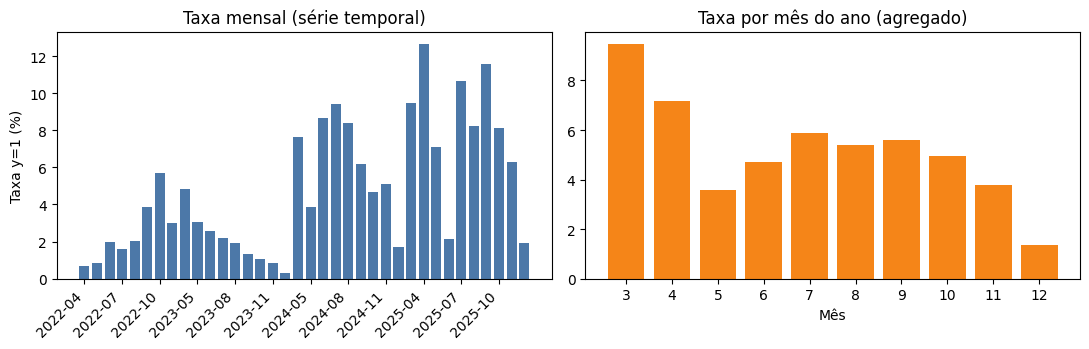

In [9]:
# Taxa mensal e por mês do ano (agregado)
ds["ano_mes"] = ds["data"].dt.to_period("M")
mensal = (
    ds.groupby("ano_mes")
    .agg(partidas=("y", "size"), lesoes_14d=("y", "sum"))
    .assign(**{"taxa_%": lambda d: (100 * d.lesoes_14d / d.partidas).round(2)})
)
display(mensal)

ds["mes"] = ds["data"].dt.month
por_mes = (
    ds.groupby("mes")
    .agg(partidas=("y", "size"), lesoes_14d=("y", "sum"))
    .assign(**{"taxa_%": lambda d: (100 * d.lesoes_14d / d.partidas).round(2)})
)
print("Por mês do ano (2022–2025 agregados):")
display(por_mes)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = range(len(mensal))
axes[0].bar(list(x), mensal["taxa_%"], color="#4C78A8")
axes[0].set_xticks(list(x)[::3])
axes[0].set_xticklabels([str(p) for p in mensal.index[::3]], rotation=45, ha="right")
axes[0].set_ylabel("Taxa y=1 (%)")
axes[0].set_title("Taxa mensal (série temporal)")

axes[1].bar(por_mes.index.astype(str), por_mes["taxa_%"], color="#F58518")
axes[1].set_xlabel("Mês")
axes[1].set_title("Taxa por mês do ano (agregado)")
fig.tight_layout()
fig.savefig(FIG / "03_taxa_mensal.png", dpi=120)
plt.show()


**Leitura:** a série mensal mostra os dois regimes do tópico 1 (patamar bem mais alto a partir de 2024). No agregado por mês, abril (~7%) e julho–setembro (~5,5%) ficam acima e dezembro bem abaixo (~1,3%; fim de temporada, poucos jogos). Março (9,5%) tem só 316 partidas, todas de 2025 — o agregado mistura anos com taxas base diferentes, então a sazonalidade é só indicativa.

### 3.2 Densidade de jogos (`jogos_30d`)

Número de partidas com minutos nos 30 dias anteriores à observação.


jogos_30d por classe:


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
0,45337.0,3.98,2.01,0.0,3.0,4.0,5.0,9.0
1,2367.0,4.01,1.99,0.0,3.0,4.0,5.0,9.0


,partidas,lesoes_14d,taxa_%
faixa_jogos30,,,
0-2,11287,554,4.91
3-4,16625,824,4.96
5-6,14630,735,5.02
7+,5162,254,4.92


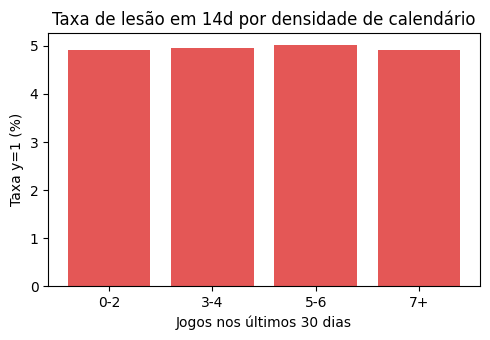

In [10]:
print("jogos_30d por classe:")
display(ds.groupby("y")["jogos_30d"].describe().round(2))

ds["faixa_jogos30"] = pd.cut(
    ds["jogos_30d"], bins=[-0.1, 2, 4, 6, 10], labels=["0-2", "3-4", "5-6", "7+"]
)
dens = (
    ds.groupby("faixa_jogos30", observed=True)
    .agg(partidas=("y", "size"), lesoes_14d=("y", "sum"))
    .assign(**{"taxa_%": lambda d: (100 * d.lesoes_14d / d.partidas).round(2)})
)
display(dens)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(dens.index.astype(str), dens["taxa_%"], color="#E45756")
ax.set_xlabel("Jogos nos últimos 30 dias")
ax.set_ylabel("Taxa y=1 (%)")
ax.set_title("Taxa de lesão em 14d por densidade de calendário")
fig.tight_layout()
fig.savefig(FIG / "03_densidade_jogos30.png", dpi=120)
plt.show()


**Leitura:** as médias de `jogos_30d` em y=0 e y=1 são praticamente iguais (3,98 vs 4,01) e a taxa por faixa é plana (~4,9–5,0% de 0–2 a 7+ jogos). Sozinha, a densidade de jogos nos 30 dias anteriores não separa as classes.

### 3.3 Dias desde a última partida

Intervalo desde o jogo anterior com minutos (recuperação / congestionamento).


dias_desde_ultima_partida por classe:


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
0,45323.0,10.45,26.02,1.0,3.0,5.0,8.0,1302.0
1,2367.0,9.64,20.84,2.0,3.0,5.0,8.0,385.0


,partidas,lesoes_14d,taxa_%
faixa_descanso,,,
1-3,13257,703,5.30
4-5,11553,611,5.29
6-7,9227,418,4.53
8-14,8137,382,4.69
15-30,3039,137,4.51
30+,2477,116,4.68


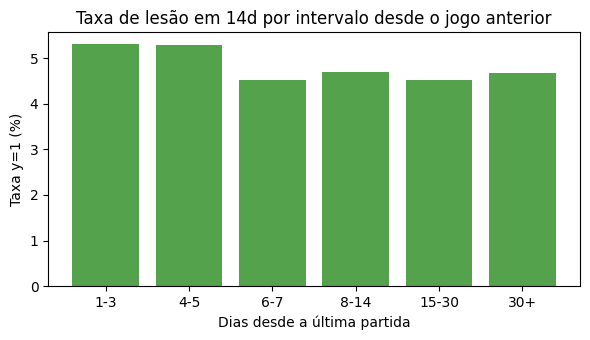

In [11]:
print("dias_desde_ultima_partida por classe:")
display(ds.groupby("y")["dias_desde_ultima_partida"].describe().round(2))

ds["faixa_descanso"] = pd.cut(
    ds["dias_desde_ultima_partida"],
    bins=[0, 3, 5, 7, 14, 30, 2000],
    labels=["1-3", "4-5", "6-7", "8-14", "15-30", "30+"],
)
desc = (
    ds.groupby("faixa_descanso", observed=True)
    .agg(partidas=("y", "size"), lesoes_14d=("y", "sum"))
    .assign(**{"taxa_%": lambda d: (100 * d.lesoes_14d / d.partidas).round(2)})
)
display(desc)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(desc.index.astype(str), desc["taxa_%"], color="#54A24B")
ax.set_xlabel("Dias desde a última partida")
ax.set_ylabel("Taxa y=1 (%)")
ax.set_title("Taxa de lesão em 14d por intervalo desde o jogo anterior")
fig.tight_layout()
fig.savefig(FIG / "03_descanso.png", dpi=120)
plt.show()


**Leitura:** intervalos curtos (1–5 dias) têm taxa um pouco maior (~5,3%) que intervalos de 6+ dias (~4,5–4,7%). O efeito é pequeno e pode refletir exposição (quem joga a cada 3 dias é titular e seguirá jogando nos 14 dias seguintes) mais do que fadiga. Congestionamento extremo não explode a taxa neste *proxy* público.

---
**Fim do tópico 3.** Próximo: auditoria do alvo e deriva de registro.

## 4. Auditoria do alvo e deriva de registro

Objetivo: antes de modelar, medir **quanta informação independente** existe no alvo e **o quanto a fonte (Transfermarkt) mudou ao longo dos anos**. Esses diagnósticos definem o tamanho amostral efetivo, o protocolo de validação e o que pode (ou não) ser concluído na Fase 5.

O que entra aqui:
- episódios únicos por trás das linhas `y=1` (janelas de 14 dias se sobrepõem)
- defasagem entre a última partida e o início da lesão (lesões ocorridas em jogo)
- inconsistências de datas (jogou durante lesão registrada)
- deriva por ano (gravidade, texto) e por clube
- validação adversarial: as features denunciam o período?

### 4.1 Episódios únicos × linhas positivas

Um jogador que atua a cada 3–4 dias tem várias partidas rotuladas com a **mesma** lesão. Contamos quantos episódios distintos geram as linhas `y=1`.

In [12]:
import numpy as np

# Episódios de lesão-alvo que geram pelo menos uma linha y=1
ds["pid"] = ds["player_id"].astype(str)
alvo = inj.loc[inj["conta_como_alvo"]].copy()
alvo["pid"] = alvo["player_id"].astype(str)

pos = ds.loc[ds["y"].eq(1), ["pid", "data", "ano"]]
par = pos.merge(alvo[["pid", "data_inicio"]], on="pid")
par = par.loc[(par["data_inicio"] > par["data"]) & (par["data_inicio"] <= par["data"] + pd.Timedelta(days=14))]

episodios = (
    par.groupby("ano")
    .apply(lambda g: g[["pid", "data_inicio"]].drop_duplicates().shape[0], include_groups=False)
    .rename("episodios_unicos")
)
resumo = pd.concat([pos.groupby("ano").size().rename("linhas_y1"), episodios], axis=1)
resumo["linhas_por_episodio"] = (resumo["linhas_y1"] / resumo["episodios_unicos"]).round(2)
resumo["jogadores_com_y1"] = pos.groupby("ano")["pid"].nunique()
display(resumo)

linhas_ep = par.groupby(["pid", "data_inicio"]).size()
print("Linhas y=1 por episódio — distribuição:")
print(linhas_ep.value_counts().sort_index().to_string())

,linhas_y1,episodios_unicos,linhas_por_episodio,jogadores_com_y1
ano,,,,
2022,308,150,2.05,129
2023,233,121,1.93,108
2024,828,416,1.99,279
2025,998,525,1.90,343


Linhas y=1 por episódio — distribuição:
1    396
2    516
3    249
4     47
5      4


**Leitura:** as 2.367 linhas `y=1` vêm de **1.212 episódios** independentes (150 / 121 / 416 / 525 por ano) — cada lesão rotula em média ~2 partidas. O treino 2022–23 tem só **271 episódios**. Consequências para a Fase 5: (i) esse é o tamanho amostral efetivo, que limita a complexidade dos modelos (MLP pequeno); (ii) intervalos de confiança precisam de *bootstrap* por jogador; (iii) positivas são quase duplicatas, o que torna o SMOTE ainda menos indicado.

### 4.2 Defasagem entre a última partida e o início da lesão

Para cada lesão-alvo, os dias entre a **última partida jogada** (qualquer competição) e a data de início registrada. Um pico em 0–1 dia indica lesões sofridas **em jogo** — e mostra como elas caem no alvo atual (dia 0 é excluído da amostra; dia +1 vira `y=1` da partida anterior).

Lesões-alvo no período: 2901
Defasagem 0 ou 1 dia: 55.2%
Última partida foi BRA1 (entre as defasagens 0–1): 45.3%


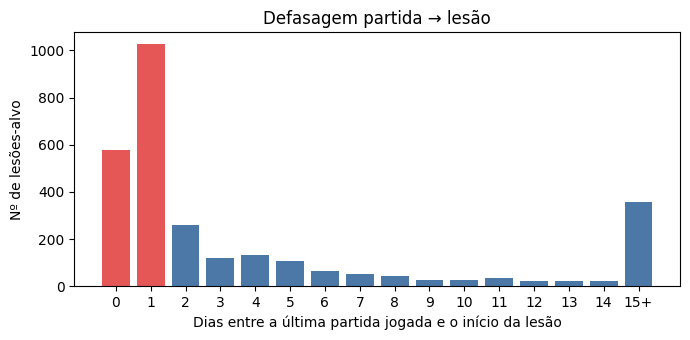

In [13]:
perf = pd.read_csv(
    PROC / "performance_raw.csv",
    usecols=["player_id", "data", "competicao", "participacao", "minutos"],
    parse_dates=["data"], dtype={"player_id": str},
)
jogadas = perf.loc[perf["participacao"].eq("played")].rename(columns={"player_id": "pid"})

anos_ds = sorted(ds["ano"].unique())
les_periodo = alvo.loc[alvo["data_inicio"].dt.year.isin(anos_ds)].dropna(subset=["data_inicio"])
ultima = pd.merge_asof(
    les_periodo.sort_values("data_inicio"),
    jogadas[["pid", "data", "competicao"]].sort_values("data"),
    left_on="data_inicio", right_on="data", by="pid", direction="backward",
)
ultima["defasagem"] = (ultima["data_inicio"] - ultima["data"]).dt.days

dist = ultima["defasagem"].clip(upper=15).value_counts().sort_index()
dist.index = [str(i) if i < 15 else "15+" for i in dist.index]
print("Lesões-alvo no período:", len(ultima))
print("Defasagem 0 ou 1 dia:", f"{ultima['defasagem'].le(1).mean():.1%}")
print("Última partida foi BRA1 (entre as defasagens 0–1):",
      f"{ultima.loc[ultima['defasagem'].le(1), 'competicao'].eq('BRA1').mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
cores = ["#E45756" if i in ("0", "1") else "#4C78A8" for i in dist.index]
ax.bar(dist.index, dist.values, color=cores)
ax.set_xlabel("Dias entre a última partida jogada e o início da lesão")
ax.set_ylabel("Nº de lesões-alvo")
ax.set_title("Defasagem partida → lesão")
fig.tight_layout()
fig.savefig(FIG / "04_defasagem_partida_lesao.png", dpi=120)
plt.show()

**Leitura:** **55%** das lesões-alvo começam no dia da última partida ou no dia seguinte — a lesão em jogo (ou registrada no dia seguinte a ele) é o caso típico, não a exceção. O alvo atual trata esses casos de forma inconsistente: início no dia 0 sai da amostra, início no dia +1 vira `y=1` da própria partida. Na engenharia de features vamos testar a janela [d, d+14] (incluindo o dia do jogo) como análise de sensibilidade, mantendo as features estritamente pré-jogo.

### 4.3 Inconsistências de datas

Partidas **jogadas** estritamente dentro de um intervalo de lesão registrado (margem de 1 dia em cada ponta) indicam erro de data no Transfermarkt. Também checamos *heaping* (concentração artificial) no dia do mês.

In [14]:
lesoes_int = alvo.dropna(subset=["data_inicio", "data_fim"])[["pid", "data_inicio", "data_fim", "dias_parado"]]
cruz = jogadas[["pid", "data", "competicao"]].merge(lesoes_int, on="pid")
dentro = cruz.loc[
    (cruz["data"] > cruz["data_inicio"] + pd.Timedelta(days=1))
    & (cruz["data"] < cruz["data_fim"] - pd.Timedelta(days=1))
]
dentro_bra = dentro.loc[dentro["competicao"].eq("BRA1") & dentro["data"].dt.year.isin(anos_ds)]
print(f"Partidas jogadas dentro de lesão registrada (todas as competições): {len(dentro):,} "
      f"| jogadores: {dentro['pid'].nunique()} | episódios: {dentro[['pid','data_inicio']].drop_duplicates().shape[0]}")
print(f"  … só BRA1 no período do dataset: {len(dentro_bra):,}")
print("Dias parado desses episódios (mediana):", dentro.drop_duplicates(["pid", "data_inicio"])["dias_parado"].median())

dia_mes = les_periodo["data_inicio"].dt.day.value_counts().sort_index()
print(f"\nHeaping: lesões com início no dia 1 do mês = {dia_mes.get(1, 0)} "
      f"(média dos outros dias = {dia_mes.drop(1).mean():.1f})")

Partidas jogadas dentro de lesão registrada (todas as competições): 452 | jogadores: 213 | episódios: 259
  … só BRA1 no período do dataset: 78
Dias parado desses episódios (mediana): 41.0

Heaping: lesões com início no dia 1 do mês = 134 (média dos outros dias = 92.2)


**Leitura:** 452 partidas jogadas caem dentro de um intervalo de lesão registrado (259 episódios, 213 jogadores; 78 delas na Série A do período). A mediana desses episódios é longa (41 dias): o mais provável é `data_fim` registrada tarde (o jogador voltou antes). Há também um leve *heaping* no dia 1 do mês (134 contra ~92 nos outros dias): parte das datas é aproximada. São poucos casos para afetar o alvo, mas atributos de “retorno de lesão” devem usar a primeira partida após o início, não só `data_fim`.

### 4.4 Deriva por ano: o salto é só de lesões curtas?

Se o Transfermarkt antes registrava só as lesões graves, um alvo restrito a lesões com afastamento mínimo deveria ter **prevalência estável** entre os anos.

Perfil dos episódios registrados por ano de início:


,episodios,mediana_dias,pct_menos_7d,pct_outras
ano,,,,
2019,303,20.0,14.5,24.8
2020,296,20.0,12.5,32.4
2021,343,21.0,9.3,31.8
2022,433,30.0,7.2,25.9
2023,516,27.5,7.9,22.1
2024,912,25.0,6.6,14.9
2025,1040,24.0,8.5,16.3
2026,681,23.0,11.3,15.1


Taxa de y=1 (%) por ano e critério de gravidade:


,atual,>=7 dias,>=14 dias,>=28 dias,>=1 jogo perdido
ano,,,,,
2022,2.58,2.43,2.03,1.62,2.54
2023,1.95,1.78,1.50,1.10,1.87
2024,6.94,6.46,5.25,2.78,6.88
2025,8.37,7.59,5.82,3.48,8.26


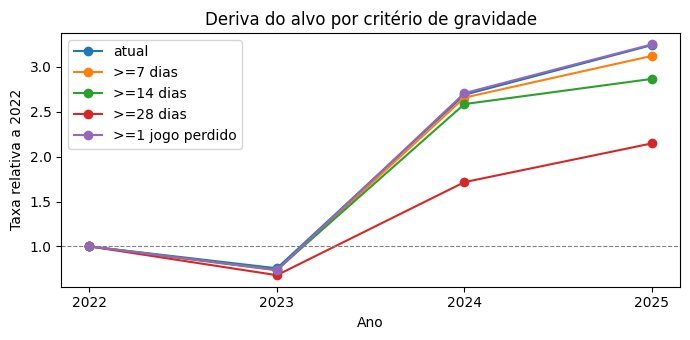

In [15]:
a = alvo.loc[alvo["data_inicio"].dt.year.between(2019, max(anos_ds) + 1)].copy()
a["ano"] = a["data_inicio"].dt.year
perfil_ano = a.groupby("ano").agg(
    episodios=("pid", "size"),
    mediana_dias=("dias_parado", "median"),
    pct_menos_7d=("dias_parado", lambda x: round(100 * (x < 7).mean(), 1)),
    pct_outras=("categoria_lesao", lambda x: round(100 * (x == "outras").mean(), 1)),
)
print("Perfil dos episódios registrados por ano de início:")
display(perfil_ano)

def taxa_alvo_restrito(mask_lesao, n_dias=14):
    # y alternativo: lesão-alvo que satisfaz o critério em (d, d+n]
    sub = alvo.loc[mask_lesao, ["pid", "data_inicio"]]
    m = ds[["pid", "data"]].reset_index().merge(sub, on="pid")
    hit = m.loc[(m["data_inicio"] > m["data"]) & (m["data_inicio"] <= m["data"] + pd.Timedelta(days=n_dias)), "index"].unique()
    return pd.Series(ds.index.isin(hit), index=ds.index).groupby(ds["ano"]).mean().mul(100).round(2)

grav = pd.DataFrame({
    "atual": ds.groupby("ano")["y"].mean().mul(100).round(2),
    ">=7 dias": taxa_alvo_restrito(alvo["dias_parado"] >= 7),
    ">=14 dias": taxa_alvo_restrito(alvo["dias_parado"] >= 14),
    ">=28 dias": taxa_alvo_restrito(alvo["dias_parado"] >= 28),
    ">=1 jogo perdido": taxa_alvo_restrito(alvo["jogos_perdidos"] >= 1),
})
print("Taxa de y=1 (%) por ano e critério de gravidade:")
display(grav)

fig, ax = plt.subplots(figsize=(7, 3.5))
(grav / grav.loc[min(anos_ds)]).plot(ax=ax, marker="o")
ax.axhline(1, color="gray", ls="--", lw=0.8)
ax.set_ylabel(f"Taxa relativa a {min(anos_ds)}")
ax.set_xlabel("Ano")
ax.set_xticks(anos_ds)
ax.set_title("Deriva do alvo por critério de gravidade")
fig.tight_layout()
fig.savefig(FIG / "04_deriva_por_gravidade.png", dpi=120)
plt.show()

**Leitura:** a hipótese “antes o site só registrava lesões graves” **não se sustenta**. A fração de lesões curtas (<7 dias) fica estável em 7–9% e a taxa sobe ~2,5–3× em **todos** os critérios de gravidade, inclusive ≥28 dias parado (1,1–1,6% → 2,8–3,5%). O que muda é a **cobertura** geral do registro (o dobro de episódios) e o detalhamento do texto (`outras` cai de ~26% para ~15%). Um alvo por gravidade não resolve a deriva e fica só como análise de robustez.

### 4.5 Deriva por clube

Se o salto vier de mudança global na fonte, deveria ser parecido entre clubes. Comparamos a taxa de `y=1` de cada clube em 2022–23 com os anos seguintes.

periodo,2022-23,2024,2025,razao_2024,razao_2025
nome_clube,,,,,
SC Internacional,3.25,10.37,11.45,3.19,3.52
EC Juventude,5.98,10.25,8.29,1.71,1.39
Fluminense FC,1.27,10.23,7.55,8.06,5.94
CR Flamengo,2.47,9.25,8.12,3.74,3.29
Atlético Mineiro,3.25,8.95,5.55,2.75,1.71
Grêmio FBPA,2.34,7.82,12.67,3.34,5.41
RB Bragantino,2.24,7.78,9.11,3.47,4.07
Fortaleza EC,1.25,7.19,9.63,5.75,7.70
São Paulo FC,4.90,7.18,10.81,1.47,2.21


Razão 2024 / 2022-23 entre clubes: mediana 3.48 | min 1.13 | max 9.66 | n=18
Razão 2025 / 2022-23 entre clubes: mediana 3.52 | min 1.39 | max 13.18 | n=17


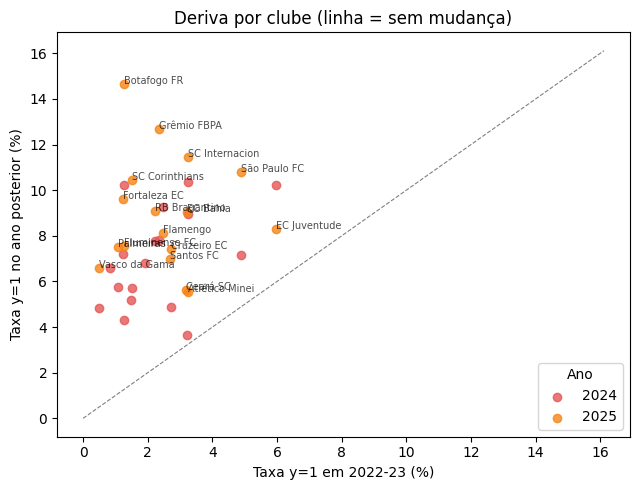

In [16]:
ds["periodo"] = np.where(ds["ano"] <= 2023, "2022-23", ds["ano"].astype(str))
por_clube = ds.groupby(["nome_clube", "periodo"]).agg(n=("y", "size"), taxa=("y", "mean")).unstack("periodo")
taxa_c = por_clube["taxa"].mul(100).round(2)
n_c = por_clube["n"]
depois = [p for p in taxa_c.columns if p != "2022-23"]
# só clubes com volume razoável nos dois lados da comparação
ok = n_c["2022-23"].ge(500) & n_c[depois].ge(300).any(axis=1)
tab = taxa_c.loc[ok].sort_values(depois[0], ascending=False)
for p in depois:
    tab[f"razao_{p}"] = (tab[p] / tab["2022-23"]).round(2)
display(tab)
for p in depois:
    r = tab[f"razao_{p}"].replace(np.inf, np.nan).dropna()
    print(f"Razão {p} / 2022-23 entre clubes: mediana {r.median():.2f} | min {r.min():.2f} | max {r.max():.2f} | n={len(r)}")

fig, ax = plt.subplots(figsize=(6.5, 5))
cores_p = ["#E45756", "#F58518", "#54A24B"]
lim = 0
for p, cor in zip(depois, cores_p):
    t = tab.dropna(subset=[p])
    ax.scatter(t["2022-23"], t[p], color=cor, label=p, alpha=0.8)
    lim = max(lim, t["2022-23"].max(), t[p].max())
    for nome, row in t.iterrows():
        if p == depois[-1]:
            ax.annotate(nome.replace("SE ", "").replace("CR ", "")[:14], (row["2022-23"], row[p]), fontsize=7, alpha=0.7)
ax.plot([0, lim * 1.1], [0, lim * 1.1], color="gray", ls="--", lw=0.8)
ax.set_xlabel("Taxa y=1 em 2022-23 (%)")
ax.set_ylabel("Taxa y=1 no ano posterior (%)")
ax.set_title("Deriva por clube (linha = sem mudança)")
ax.legend(title="Ano")
fig.tight_layout()
fig.savefig(FIG / "04_deriva_por_clube.png", dpi=120)
plt.show()

**Leitura:** o salto **não é uniforme**: a razão entre a taxa posterior e a de 2022–23 tem mediana ~3,5×, mas vai de ~1,1–1,4× (Bahia, Juventude) a 9–13× (Vasco, Botafogo). A qualidade do registro depende do clube. Isso reforça manter o clube **fora** dos atributos (ele aprenderia o padrão de registro, não o risco) e validar com clubes deixados de fora.

### 4.6 Validação adversarial

Treinamos um classificador para distinguir observações de **2022–23** das de cada ano posterior usando só as features do modelo. AUC ≈ 0,5 = distribuições iguais; AUC alta = *covariate shift*. A AUC univariada de cada feature mostra **quais** denunciam o período.

In [17]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict

FEATS_ADV = [
    "minutos_7d", "minutos_cronica_4sem", "acwr", "dias_desde_ultima_partida",
    "jogos_30d", "n_lesoes_previas", "dias_desde_ultima_lesao", "idade", "titular",
]
linhas = []
for p in depois:
    sub = ds.loc[ds["periodo"].isin(["2022-23", p])]
    X = sub[FEATS_ADV].astype(float)
    alvo_adv = sub["periodo"].eq(p).astype(int)
    clf = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=42)
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    prob = cross_val_predict(clf, X, alvo_adv, groups=sub["pid"], cv=cv, method="predict_proba")[:, 1]
    print(f"AUC adversarial 2022-23 × {p} (todas as features): {roc_auc_score(alvo_adv, prob):.3f}")
    for f in FEATS_ADV:
        v = X[f].fillna(-1)  # NaN informativo (nunca lesionado / sem crônica)
        auc = roc_auc_score(alvo_adv, v)
        linhas.append({"comparacao": p, "feature": f, "auc_univariada": round(max(auc, 1 - auc), 3)})

uni = pd.DataFrame(linhas).pivot(index="feature", columns="comparacao", values="auc_univariada")
uni = uni.sort_values(depois[0], ascending=False)
display(uni)

print("\nMédias por período das features de histórico:")
display(ds.groupby("periodo").agg(
    n_lesoes_previas=("n_lesoes_previas", "mean"),
    pct_nunca_lesionado=("dias_desde_ultima_lesao", lambda x: round(100 * x.isna().mean(), 1)),
    idade=("idade", "mean"),
).round(2))

AUC adversarial 2022-23 × 2024 (todas as features): 0.681


AUC adversarial 2022-23 × 2025 (todas as features): 0.750


comparacao,2024,2025
feature,,
n_lesoes_previas,0.633,0.706
dias_desde_ultima_lesao,0.563,0.592
idade,0.517,0.539
acwr,0.516,0.511
dias_desde_ultima_partida,0.516,0.500
jogos_30d,0.513,0.540
minutos_7d,0.510,0.501
minutos_cronica_4sem,0.509,0.531
titular,0.502,0.502



Médias por período das features de histórico:


,n_lesoes_previas,pct_nunca_lesionado,idade
periodo,,,
2022-23,1.69,54.0,27.05
2024,2.74,29.3,27.35
2025,3.67,19.4,27.70


**Leitura:** um classificador separa 2022–23 de 2024 com AUC 0,68 e de 2025 com 0,75 — há *covariate shift*, e ele está quase todo no **histórico de lesões**: `n_lesoes_previas` (AUC univariada 0,63–0,71) e `dias_desde_ultima_lesao` (0,56–0,59). A fatia “nunca lesionado” cai de 54% para 29% e 19%. As features de carga quase não mudam (0,50–0,54). Parte disso é natural (o histórico de cada jogador acumula com o tempo), parte é registro. Implicações: o teste 2024→2025 (registro parecido) é o mais limpo; vale testar atributos de histórico **em janela fixa** (ex.: lesões nos últimos 12 meses), menos sensíveis à cobertura antiga do site.

---
**Fim do tópico 4.** Próximo: carga × lesão.

## 5. Carga × lesão

Objetivo: testar a hipótese central do trabalho — **a carga derivada de minutos públicos se associa ao risco de lesão?**

Por causa da deriva de registro (tópico 4), comparamos faixas usando o **risco relativo ao ano**: a taxa de `y=1` de cada faixa dividida pela taxa média do ano da observação. Valor 1 = risco médio; 1,3 = 30% acima da média daquele ano. Assim, 2022–23 (registro pobre) e 2024–25 (registro rico) entram na mesma escala.

Variantes de ACWR comparadas (todas calculadas sem a partida corrente):
- **acoplada** (original): aguda 7d / média semanal de 28d (a semana aguda está dentro da crônica)
- **desacoplada**: aguda 7d / média semanal dos dias 8–28
- **EWMA** (Williams et al., 2017): médias móveis exponenciais diárias com λ = 2/(N+1), N = 7 e 28

In [18]:
def risco_relativo(df, col_faixa):
    # taxa da faixa / taxa média do ano, com IC 95% aproximado (normal)
    base = df.groupby("ano")["y"].transform("mean")
    rr = df["y"] / base
    g = pd.DataFrame({"faixa": df[col_faixa], "rr": rr, "y": df["y"]}).groupby("faixa", observed=True)
    out = g.agg(partidas=("y", "size"), lesoes_14d=("y", "sum"), risco_rel=("rr", "mean"), dp=("rr", "std"))
    out["ic95"] = 1.96 * out["dp"] / np.sqrt(out["partidas"])
    return out.drop(columns="dp").round(3)

def plota_rr(ax, tab, titulo, cor="#4C78A8"):
    x = tab.index.astype(str)
    ax.bar(x, tab["risco_rel"], yerr=tab["ic95"], color=cor, capsize=3)
    ax.axhline(1, color="gray", ls="--", lw=0.8)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylabel("Risco relativo ao ano")
    ax.tick_params(axis="x", rotation=30)

### 5.1 Distribuição da carga por classe

Minutos agudos (7d), carga crônica (média semanal 28d) e as três ACWR, separados por `y`.

y,mediana y=0,mediana y=1
minutos_7d,25.000,45.000
minutos_cronica_4sem,59.250,62.500
acwr,0.667,0.738
acwr_desacoplada,0.567,0.635
acwr_ewma,0.648,0.706
ewma_aguda,5.071,5.915
ewma_cronica,8.473,8.920


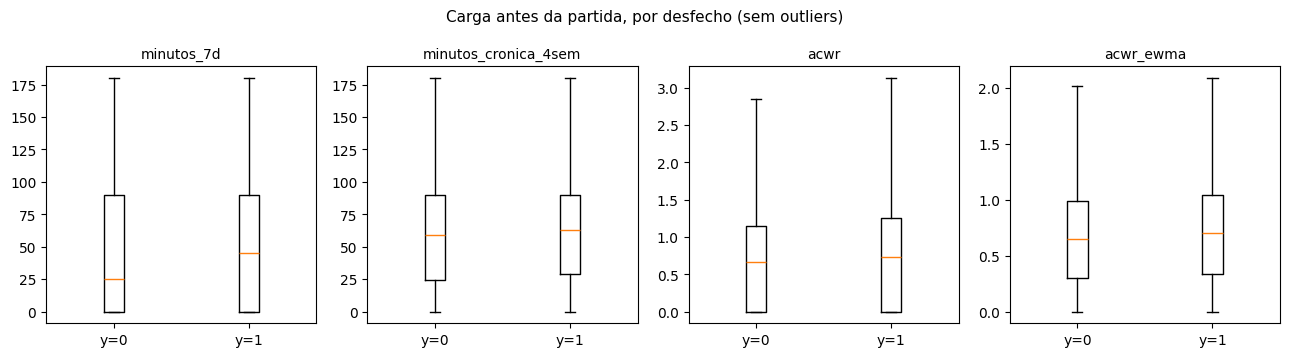

In [19]:
CARGA = ["minutos_7d", "minutos_cronica_4sem", "acwr", "acwr_desacoplada", "acwr_ewma", "ewma_aguda", "ewma_cronica"]
display(ds.groupby("y")[CARGA].median().T.rename(columns={0: "mediana y=0", 1: "mediana y=1"}).round(3))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, col in zip(axes, ["minutos_7d", "minutos_cronica_4sem", "acwr", "acwr_ewma"]):
    dados = [ds.loc[ds["y"].eq(k), col].dropna() for k in (0, 1)]
    ax.boxplot(dados, tick_labels=["y=0", "y=1"], showfliers=False)
    ax.set_title(col, fontsize=10)
fig.suptitle("Carga antes da partida, por desfecho (sem outliers)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "05_carga_por_classe.png", dpi=120)
plt.show()

**Leitura:** quem se lesiona nos 14 dias seguintes vinha jogando um pouco mais na última semana (mediana de 45 contra 25 minutos), mas as distribuições se sobrepõem quase por completo. Carga crônica e as três ACWR mudam pouco entre as classes (ACWR acoplada 0,74 vs 0,67).

### 5.2 Risco por faixas de ACWR

Faixas clássicas da literatura (zona “ótima” ~0,8–1,3; pico de risco > 1,5). Separamos dois casos especiais: **sem crônica** (ACWR indefinida) e **aguda = 0** (não jogou nos 7 dias anteriores).

ACWR acoplada


,partidas,lesoes_14d,risco_rel,ic95
faixa,,,,
sem crônica,2869,130,0.814,0.164
aguda=0,16570,767,0.993,0.083
0-0.8,8625,409,0.973,0.112
0.8-1.3,9957,518,1.051,0.107
1.3-1.5,2725,134,0.876,0.172
>=1.5,6958,409,1.102,0.125


ACWR desacoplada


,partidas,lesoes_14d,risco_rel,ic95
faixa,,,,
sem crônica,4449,223,0.926,0.143
aguda=0,16570,767,0.993,0.083
0-0.8,10798,538,1.009,0.101
0.8-1.3,6915,356,1.063,0.131
1.3-1.5,1124,51,0.807,0.259
>=1.5,7848,432,1.017,0.112


ACWR EWMA


,partidas,lesoes_14d,risco_rel,ic95
faixa,,,,
sem crônica,14,0,0.000,0.000
aguda=0,1099,51,0.984,0.322
0-0.8,27762,1302,0.981,0.063
0.8-1.3,14141,728,0.990,0.085
1.3-1.5,2063,121,1.102,0.231
>=1.5,2625,165,1.192,0.215


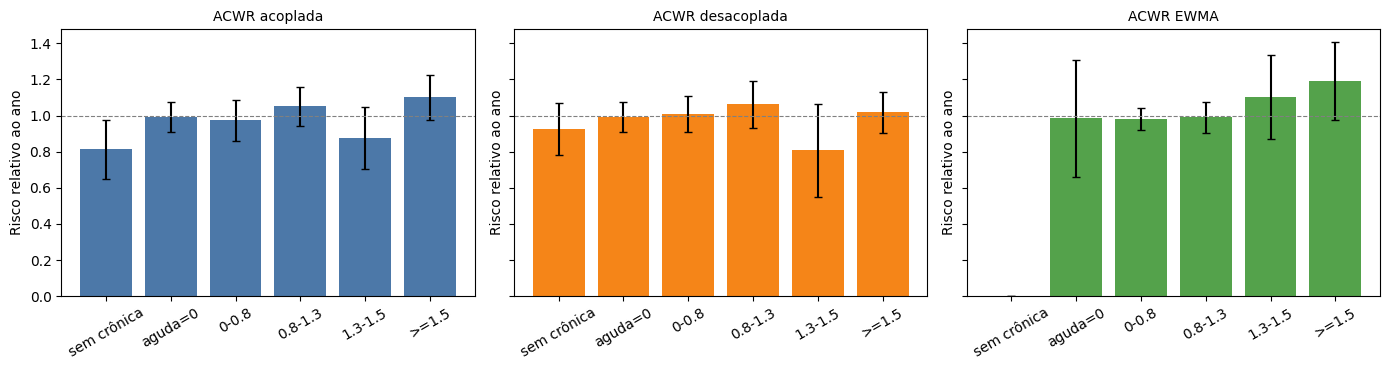

Correlação de Spearman entre as ACWR:


,acwr,acwr_desacoplada,acwr_ewma
acwr,1.000,1.000,0.843
acwr_desacoplada,1.000,1.000,0.839
acwr_ewma,0.843,0.839,1.000


In [20]:
def faixa_acwr(s, aguda):
    f = pd.cut(s, bins=[0, 0.8, 1.3, 1.5, np.inf], right=False, labels=["0-0.8", "0.8-1.3", "1.3-1.5", ">=1.5"]).astype(object)
    f[aguda.eq(0) & s.notna()] = "aguda=0"
    f[s.isna()] = "sem crônica"
    ordem = ["sem crônica", "aguda=0", "0-0.8", "0.8-1.3", "1.3-1.5", ">=1.5"]
    return pd.Categorical(f, categories=ordem, ordered=True)

ds["f_acwr"] = faixa_acwr(ds["acwr"], ds["minutos_7d"])
ds["f_acwr_desac"] = faixa_acwr(ds["acwr_desacoplada"], ds["minutos_7d"])
ds["f_acwr_ewma"] = faixa_acwr(ds["acwr_ewma"], ds["ewma_aguda"].round(6))

tabs = {nome: risco_relativo(ds, col) for nome, col in
        [("ACWR acoplada", "f_acwr"), ("ACWR desacoplada", "f_acwr_desac"), ("ACWR EWMA", "f_acwr_ewma")]}
for nome, t in tabs.items():
    print(nome); display(t)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (nome, t), cor in zip(axes, tabs.items(), ["#4C78A8", "#F58518", "#54A24B"]):
    plota_rr(ax, t, nome, cor)
fig.tight_layout()
fig.savefig(FIG / "05_risco_por_faixa_acwr.png", dpi=120)
plt.show()

print("Correlação de Spearman entre as ACWR:")
display(ds[["acwr", "acwr_desacoplada", "acwr_ewma"]].corr(method="spearman").round(3))

**Leitura:** a ACWR acoplada e a desacoplada têm correlação de Spearman **1,00**: uma é transformação monotônica da outra (desacoplada = 3·r/(4 − r)), então ordenam os jogadores da mesma forma; só os pontos de corte mudam. Nenhuma das duas mostra a curva em “J” da literatura: os riscos relativos oscilam entre 0,8 e 1,1 com intervalos que cruzam 1. A **EWMA** é a única com gradiente consistente (0,98 → 0,99 → 1,10 → 1,19 de <0,8 até ≥1,5), no sentido esperado, mas fraco e com IC largo nas faixas altas (poucas partidas). Para a modelagem: ficar com EWMA + uma ACWR clássica (a acoplada, que já é limitada a 4); a desacoplada não acrescenta informação de ordenação.

### 5.3 Carga aguda e crônica

Os componentes da razão separados: risco relativo por faixa de minutos nos 7 dias e por quintil de carga crônica.

Minutos nos 7 dias anteriores:


,partidas,lesoes_14d,risco_rel,ic95,faixa_minutos
faixa,,,,,
0,19439,897,0.966,0.075,0–0
1-45,7595,341,0.858,0.107,1–45
46-90,18011,985,1.083,0.080,46–90
91-135,918,52,1.155,0.383,91–135
136+,1741,92,1.059,0.252,136–180


Carga crônica (média semanal, 28 dias):


,partidas,lesoes_14d,risco_rel,ic95,faixa_min_sem
faixa,,,,,
Q1 (baixa),9608,410,0.811,0.092,0–20
Q2,9997,484,0.934,0.098,20–45
Q3,9290,477,1.058,0.111,45–68
Q4,9310,510,1.159,0.119,68–94
Q5 (alta),9499,486,1.048,0.110,95–180


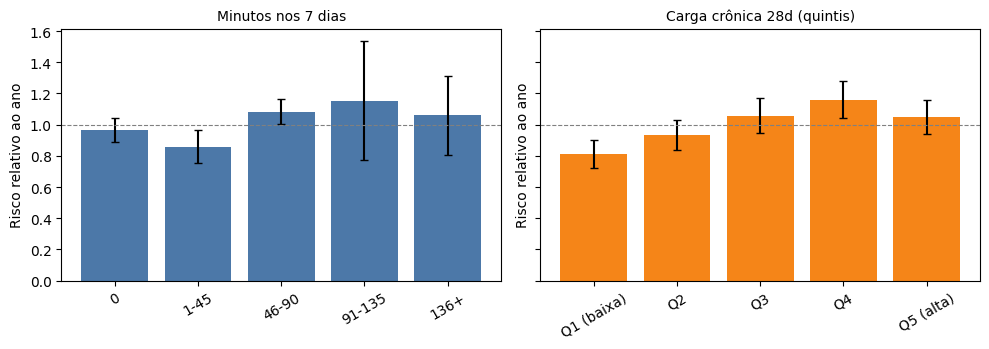

In [21]:
# ~35% das linhas têm 0 min nos 7 dias: faixas explícitas evitam quintis empatados
ds["q_aguda"] = pd.cut(ds["minutos_7d"], bins=[-1, 0, 45, 90, 135, 1000], labels=["0", "1-45", "46-90", "91-135", "136+"])
ds["q_cronica"] = pd.qcut(ds["minutos_cronica_4sem"], 5, labels=["Q1 (baixa)", "Q2", "Q3", "Q4", "Q5 (alta)"])
t_ag = risco_relativo(ds, "q_aguda")
t_cr = risco_relativo(ds, "q_cronica")
t_ag["faixa_minutos"] = ds.groupby("q_aguda", observed=True)["minutos_7d"].agg(lambda x: f"{x.min():.0f}–{x.max():.0f}")
t_cr["faixa_min_sem"] = ds.groupby("q_cronica", observed=True)["minutos_cronica_4sem"].agg(lambda x: f"{x.min():.0f}–{x.max():.0f}")
print("Minutos nos 7 dias anteriores:"); display(t_ag)
print("Carga crônica (média semanal, 28 dias):"); display(t_cr)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
plota_rr(axes[0], t_ag, "Minutos nos 7 dias", "#4C78A8")
plota_rr(axes[1], t_cr, "Carga crônica 28d (quintis)", "#F58518")
fig.tight_layout()
fig.savefig(FIG / "05_risco_quintis_carga.png", dpi=120)
plt.show()

**Leitura:** a carga **crônica** tem o gradiente mais claro: risco relativo 0,81 no quintil mais baixo, subindo até ~1,16 no Q4. Na aguda, quem jogou 46+ minutos na semana tem risco ~1,08–1,16 contra 0,86–0,97 de quem jogou pouco ou nada. A leitura mais provável é **exposição**, não sobrecarga: titular regular continua jogando nos 14 dias seguintes e tem mais oportunidades de se lesionar. Isso reforça o atributo de **jogos agendados nos próximos 14 dias** (exposição futura, informação pública e conhecida antes) para separar exposição de carga.

### 5.4 Histórico de lesões

Número de lesões-alvo anteriores e tempo desde a última. Lembrete do tópico 4: esses atributos também carregam a deriva de registro.

Nº de lesões prévias:


,partidas,lesoes_14d,risco_rel,ic95
faixa,,,,
0,18701,482,0.681,0.069
1,9246,437,0.990,0.110
2,5460,312,1.105,0.145
3-4,6297,391,1.055,0.122
5+,8000,745,1.642,0.137


Dias desde a última lesão:


,partidas,lesoes_14d,risco_rel,ic95
faixa,,,,
<=30,1441,185,2.009,0.320
31-90,4876,484,1.559,0.153
91-180,4703,352,1.237,0.149
181-365,5518,313,1.065,0.142
1-2 anos,6050,304,0.998,0.132
>2 anos,6415,247,1.051,0.151
nunca,18701,482,0.681,0.069


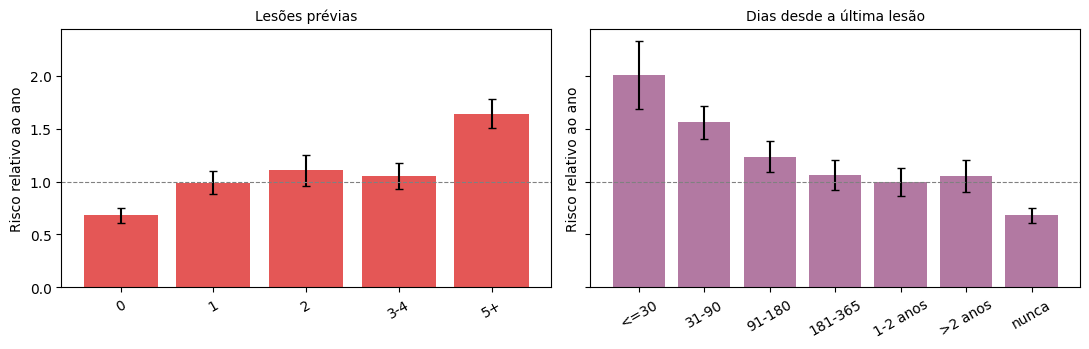

In [22]:
ds["f_n_prev"] = pd.cut(ds["n_lesoes_previas"], bins=[-1, 0, 1, 2, 4, 100], labels=["0", "1", "2", "3-4", "5+"])
f_dias = pd.cut(ds["dias_desde_ultima_lesao"], bins=[0, 30, 90, 180, 365, 730, 100000],
                labels=["<=30", "31-90", "91-180", "181-365", "1-2 anos", ">2 anos"]).astype(object)
f_dias[ds["dias_desde_ultima_lesao"].isna()] = "nunca"
ds["f_dias_lesao"] = pd.Categorical(f_dias, categories=["<=30", "31-90", "91-180", "181-365", "1-2 anos", ">2 anos", "nunca"], ordered=True)

t_np = risco_relativo(ds, "f_n_prev")
t_dl = risco_relativo(ds, "f_dias_lesao")
print("Nº de lesões prévias:"); display(t_np)
print("Dias desde a última lesão:"); display(t_dl)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
plota_rr(axes[0], t_np, "Lesões prévias", "#E45756")
plota_rr(axes[1], t_dl, "Dias desde a última lesão", "#B279A2")
fig.tight_layout()
fig.savefig(FIG / "05_risco_historico.png", dpi=120)
plt.show()

**Leitura:** o **histórico** é o sinal mais forte da EDA. Quem nunca teve lesão registrada tem risco relativo 0,68; com 5+ lesões prévias, 1,64. A recência pesa ainda mais: lesão nos últimos 30 dias → risco 2,0; 31–90 dias → 1,56; 91–180 → 1,24; depois de 6 meses o efeito some (~1,0). É o padrão de reincidência descrito na literatura. Ressalva do tópico 4: “nunca lesionado” também reflete cobertura do site, então parte do efeito do grupo 0 é de registro.

### 5.5 Poder discriminante de cada atributo, ano a ano

AUC-ROC **univariada** de cada atributo para separar `y=1` de `y=0`, calculada **dentro de cada ano** (neutraliza a diferença de taxa base entre anos). 0,5 = nenhum sinal. Mostramos max(AUC, 1−AUC) e o sentido da associação (+ = valor alto, mais risco). Nulos recebem um valor fora da escala para que “nunca lesionado” e “sem crônica” contem como informação.

ano,2022,2023,2024,2025,sentido
atributo,,,,,
n_lesoes_previas,0.582,0.611,0.586,0.611,++++
dias_desde_ultima_lesao,0.591,0.600,0.593,0.604,−−−−
idade,0.534,0.510,0.530,0.549,+−++
ewma_aguda,0.525,0.562,0.531,0.531,−+++
acwr_ewma,0.522,0.530,0.531,0.528,−+++
titular,0.536,0.574,0.523,0.528,++++
ewma_cronica,0.525,0.574,0.525,0.524,−+++
minutos_cronica_4sem,0.515,0.575,0.527,0.521,−+++
acwr_desacoplada,0.527,0.511,0.528,0.520,−+++


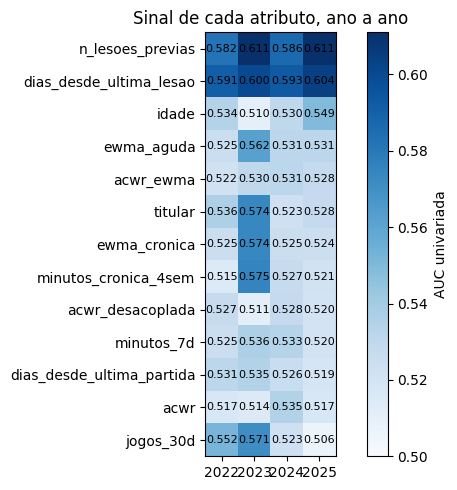

In [23]:
from sklearn.metrics import roc_auc_score

ATRIB = {
    "minutos_7d": 0, "minutos_cronica_4sem": 0, "acwr": -1, "acwr_desacoplada": -1, "acwr_ewma": -1,
    "ewma_aguda": 0, "ewma_cronica": 0, "jogos_30d": 0, "dias_desde_ultima_partida": 999,
    "n_lesoes_previas": 0, "dias_desde_ultima_lesao": 99999, "idade": 0, "titular": 0,
}
reg = []
for a, sub in ds.groupby("ano"):
    for f, nulo in ATRIB.items():
        auc = roc_auc_score(sub["y"], sub[f].astype(float).fillna(nulo))
        reg.append({"ano": a, "atributo": f, "auc": max(auc, 1 - auc), "sentido": "+" if auc >= 0.5 else "−"})
auc_ano = pd.DataFrame(reg)
tab_auc = auc_ano.pivot(index="atributo", columns="ano", values="auc").round(3)
tab_auc["sentido"] = auc_ano.groupby("atributo")["sentido"].agg(lambda x: "".join(x))
tab_auc = tab_auc.sort_values(tab_auc.columns[-2], ascending=False)
display(tab_auc)

fig, ax = plt.subplots(figsize=(6.5, 5))
mat = tab_auc.drop(columns="sentido")
im = ax.imshow(mat.values, cmap="Blues", vmin=0.5, vmax=max(0.6, mat.values.max()))
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="AUC univariada")
ax.set_title("Sinal de cada atributo, ano a ano")
fig.tight_layout()
fig.savefig(FIG / "05_auc_univariada_por_ano.png", dpi=120)
plt.show()

**Leitura:** calculada dentro de cada ano (sem efeito de taxa base), a AUC univariada confirma o quadro. O **histórico** é o sinal mais forte e **estável** (`n_lesoes_previas` e `dias_desde_ultima_lesao` em 0,58–0,61 nos quatro anos). Os atributos de **carga** ficam em 0,51–0,57 e **mudam de sentido** em 2022 (carga alta associada a menos risco) em relação a 2023–25; `jogos_30d` cai de 0,55–0,57 (2022–23) para 0,51–0,52 (2024–25). Conclusão da EDA para a hipótese central: a carga derivada de minutos públicos tem sinal **fraco e instável** quando vista sozinha. A Fase 5 precisa responder, com ablação, se ela acrescenta algo **além** do histórico e do perfil.

---
**Fim do tópico 5.** Próximo: comparativos entre clubes e posições.

## 6. Comparativos entre clubes e posições

Objetivo: comparar **risco** e **carga** entre clubes e posições, e checar se onde se joga mais é onde se lesiona mais. Como nos tópicos anteriores, o risco é medido **relativo ao ano** (taxa da observação ÷ taxa média do ano), para não confundir clube/posição com a deriva de registro.

### 6.1 Clubes: risco e carga

Clubes com pelo menos 1.500 partidas-jogador no período (≈ 2 temporadas na Série A).

,temporadas,partidas,lesoes_14d,risco_rel,minutos_7d,jogos_30d,acwr_ewma,pct_titular,idade,n_lesoes_previas,ic95
nome_clube,,,,,,,,,,,
São Paulo FC,4,2371,164,1.64,47.94,4.17,0.72,69.89,27.17,3.71,0.29
EC Juventude,3,1810,148,1.59,35.18,3.14,0.62,69.12,27.78,1.55,0.29
SC Internacional,4,2392,169,1.44,43.65,3.92,0.71,69.77,27.45,4.58,0.25
Grêmio FBPA,3,1799,137,1.28,38.68,3.71,0.69,69.21,27.40,3.66,0.25
Atlético Mineiro,4,2334,122,1.18,51.96,4.56,0.72,71.47,28.37,3.53,0.24
CR Flamengo,4,2338,130,1.17,52.35,4.67,0.74,71.00,27.19,5.37,0.24
EC Bahia,3,1792,95,1.08,45.81,4.27,0.69,69.53,27.27,2.57,0.27
Santos FC,3,1788,74,1.08,38.36,3.66,0.66,69.85,26.26,2.10,0.29
RB Bragantino,4,2412,129,1.04,39.02,3.62,0.68,69.03,24.26,1.62,0.21


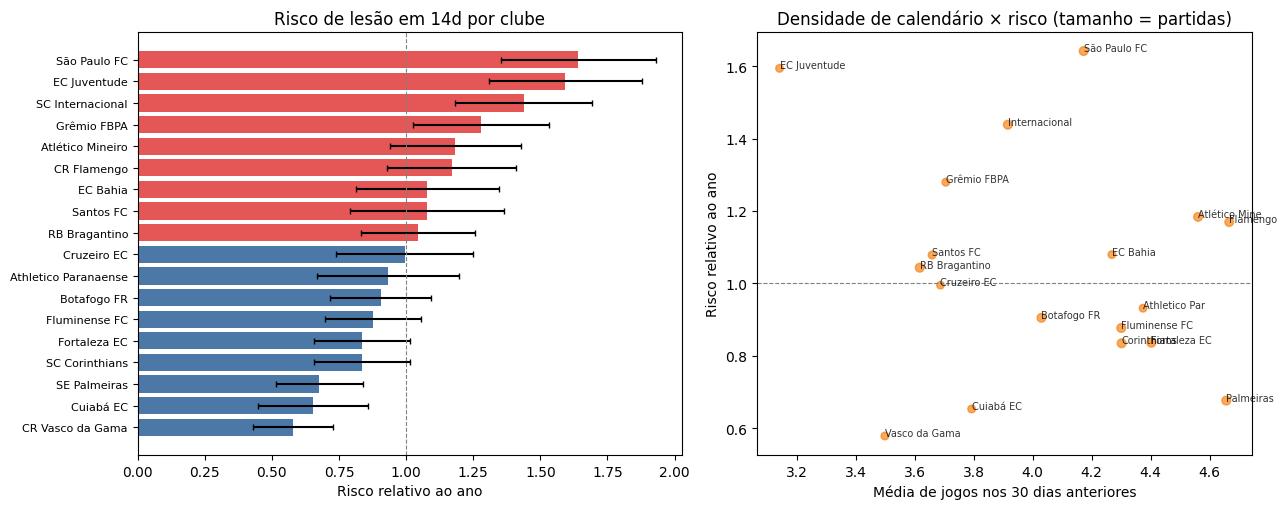

Correlação de Spearman entre atributos médios do clube e risco relativo:
  jogos_30d          rho = -0.12  (p = 0.63, n = 18)
  minutos_7d         rho = -0.03  (p = 0.91, n = 18)
  acwr_ewma          rho = +0.20  (p = 0.43, n = 18)
  pct_titular        rho = +0.09  (p = 0.72, n = 18)
  idade              rho = +0.14  (p = 0.58, n = 18)
  n_lesoes_previas   rho = +0.49  (p = 0.04, n = 18)


In [24]:
base_ano = ds.groupby("ano")["y"].transform("mean")
ds["rr"] = ds["y"] / base_ano

clube = ds.groupby("nome_clube").agg(
    temporadas=("ano", "nunique"),
    partidas=("y", "size"),
    lesoes_14d=("y", "sum"),
    risco_rel=("rr", "mean"),
    dp=("rr", "std"),
    minutos_7d=("minutos_7d", "mean"),
    jogos_30d=("jogos_30d", "mean"),
    acwr_ewma=("acwr_ewma", "mean"),
    pct_titular=("titular", "mean"),
    idade=("idade", "mean"),
    n_lesoes_previas=("n_lesoes_previas", "mean"),
)
clube["ic95"] = 1.96 * clube["dp"] / np.sqrt(clube["partidas"])
clube["pct_titular"] *= 100
clube = clube.drop(columns="dp").loc[clube["partidas"].ge(1500)].sort_values("risco_rel", ascending=False)
display(clube.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
c = clube.sort_values("risco_rel")
cores = ["#E45756" if v > 1 else "#4C78A8" for v in c["risco_rel"]]
axes[0].barh(c.index, c["risco_rel"], xerr=c["ic95"], color=cores, capsize=2)
axes[0].axvline(1, color="gray", ls="--", lw=0.8)
axes[0].set_xlabel("Risco relativo ao ano")
axes[0].set_title("Risco de lesão em 14d por clube")
axes[0].tick_params(axis="y", labelsize=8)

axes[1].scatter(clube["jogos_30d"], clube["risco_rel"], s=clube["partidas"] / 60, color="#F58518", alpha=0.7)
for nome, row in clube.iterrows():
    axes[1].annotate(nome.replace("SE ", "").replace("CR ", "").replace("SC ", "")[:13],
                     (row["jogos_30d"], row["risco_rel"]), fontsize=7, alpha=0.8)
axes[1].axhline(1, color="gray", ls="--", lw=0.8)
axes[1].set_xlabel("Média de jogos nos 30 dias anteriores")
axes[1].set_ylabel("Risco relativo ao ano")
axes[1].set_title("Densidade de calendário × risco (tamanho = partidas)")
fig.tight_layout()
fig.savefig(FIG / "06_clubes_risco_carga.png", dpi=120)
plt.show()

from scipy.stats import spearmanr
print("Correlação de Spearman entre atributos médios do clube e risco relativo:")
for col in ["jogos_30d", "minutos_7d", "acwr_ewma", "pct_titular", "idade", "n_lesoes_previas"]:
    r, p = spearmanr(clube[col], clube["risco_rel"])
    print(f"  {col:18s} rho = {r:+.2f}  (p = {p:.2f}, n = {len(clube)})")

**Leitura:** o risco relativo varia bastante entre clubes, de 0,58 (Vasco) e 0,65–0,68 (Cuiabá, Palmeiras) até 1,44–1,64 (Internacional, Juventude, São Paulo), com vários intervalos que não cruzam 1. Mas a **carga média do clube não explica essa diferença**: as correlações com `jogos_30d` (ρ = −0,12), `minutos_7d` (−0,03) e `acwr_ewma` (+0,20) são fracas e não significativas. O Palmeiras, com o calendário mais denso (4,7 jogos/30 dias), está entre os de menor risco. A única associação relevante é com o **nº médio de lesões prévias do elenco** (ρ = +0,49; p = 0,04): clubes que registram mais lesões aparecem com mais histórico **e** mais `y=1`, outro indício de que a diferença entre clubes é em boa parte **registro**. Com 18 clubes, o poder estatístico é baixo.

### 6.2 Clubes ao longo dos anos

Taxa bruta de `y=1` por clube e ano. Mostra se o ranking de clubes é estável ou se muda junto com a deriva de registro.

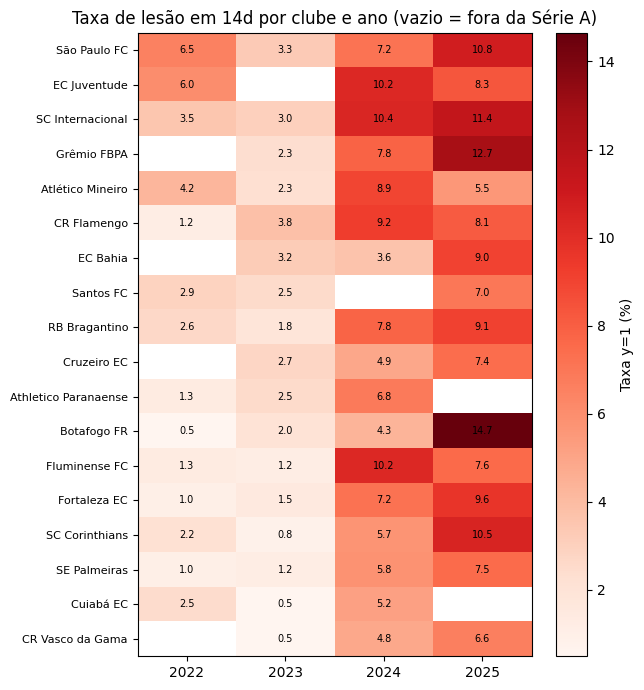

Estabilidade do ranking de clubes (Spearman entre anos):


,anos,rho,clubes
0,2022×2023,0.31,13
1,2022×2024,0.46,13
2,2022×2025,-0.08,12
3,2023×2024,0.24,16
4,2023×2025,0.19,15
5,2024×2025,0.00,15


In [25]:
mat = ds.pivot_table(index="nome_clube", columns="ano", values="y", aggfunc="mean").mul(100)
mat = mat.loc[clube.index]  # mesma ordem do 6.1
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(mat.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns)
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index, fontsize=8)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, "" if np.isnan(v) else f"{v:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Taxa y=1 (%)")
ax.set_title("Taxa de lesão em 14d por clube e ano (vazio = fora da Série A)")
fig.tight_layout()
fig.savefig(FIG / "06_clube_ano_heatmap.png", dpi=120)
plt.show()

# estabilidade do ranking: correlação de Spearman da taxa do clube entre pares de anos
anos = list(mat.columns)
pares = []
for i, a in enumerate(anos):
    for b in anos[i + 1:]:
        sub = mat[[a, b]].dropna()
        r, _ = spearmanr(sub[a], sub[b])
        pares.append({"anos": f"{a}×{b}", "rho": round(r, 2), "clubes": len(sub)})
print("Estabilidade do ranking de clubes (Spearman entre anos):")
display(pd.DataFrame(pares))

**Leitura:** o ranking de clubes **não é estável** de um ano para outro: a correlação entre anos vai de −0,08 a 0,46, e entre 2024 e 2025 (registro comparável) é **0,00**. Se o clube fosse um fator de risco persistente (gramado, departamento médico, estilo de jogo), o ranking se repetiria. Como não se repete, um atributo de clube aprenderia o ruído ou o padrão de registro de um ano específico. Isso confirma a decisão de deixar o clube fora do modelo principal.

### 6.3 Posições: carga, risco e tipo de lesão

Carga típica de cada posição, risco relativo ao ano e o perfil anatômico das lesões.

,partidas,risco_rel,minutos_jogados,minutos_7d,jogos_30d,acwr_ewma,pct_titular,idade,ic95
posicao_grupo,,,,,,,,,
zagueiro,7161,1.20,78.53,51.12,3.73,0.68,87.78,27.84,0.14
atacante,6128,1.08,51.61,37.62,4.05,0.68,55.79,27.66,0.14
meia,9044,1.07,55.82,40.11,4.05,0.69,63.17,27.29,0.12
ponta,8341,0.95,50.57,36.10,4.00,0.69,54.67,25.81,0.10
lateral,7875,0.95,68.65,44.65,3.84,0.67,76.62,27.05,0.11
volante,6089,0.93,61.57,42.88,3.97,0.68,70.13,26.83,0.13
goleiro,3066,0.59,89.05,67.67,4.59,0.72,98.83,30.82,0.15


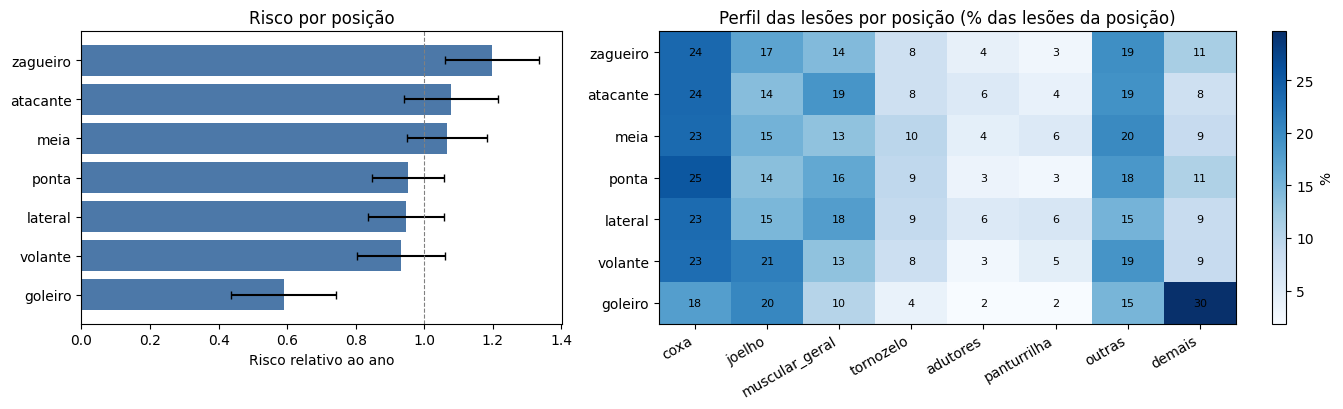

Lesões-alvo 2022–25 com posição conhecida: 2890


In [26]:
pos = ds.groupby("posicao_grupo").agg(
    partidas=("y", "size"),
    risco_rel=("rr", "mean"),
    dp=("rr", "std"),
    minutos_jogados=("minutos_jogados", "mean"),
    minutos_7d=("minutos_7d", "mean"),
    jogos_30d=("jogos_30d", "mean"),
    acwr_ewma=("acwr_ewma", "mean"),
    pct_titular=("titular", "mean"),
    idade=("idade", "mean"),
)
pos["ic95"] = 1.96 * pos["dp"] / np.sqrt(pos["partidas"])
pos["pct_titular"] *= 100
pos = pos.drop(columns="dp").sort_values("risco_rel", ascending=False)
display(pos.round(2))

# perfil anatômico: lesões-alvo 2022–25 × posição (moda do jogador no elenco)
pos_jog = (
    squad.assign(pid=squad["player_id"].astype(str), posicao_grupo=squad["posicao"].map(MAPA).fillna("outras"))
    .loc[lambda d: d["temporada"].between(2022, 2025)]
    .groupby("pid")["posicao_grupo"].agg(lambda x: x.mode().iloc[0])
)
lp = les_p.assign(pid=les_p["player_id"].astype(str))
lp["posicao_grupo"] = lp["pid"].map(pos_jog)
top_cat = ["coxa", "joelho", "muscular_geral", "tornozelo", "adutores", "panturrilha", "outras"]
lp["cat"] = lp["categoria_lesao"].where(lp["categoria_lesao"].isin(top_cat), "demais")
perfil = pd.crosstab(lp["posicao_grupo"], lp["cat"], normalize="index").mul(100)
perfil = perfil[top_cat + ["demais"]].loc[pos.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [0.8, 1.2]})
p = pos.sort_values("risco_rel")
axes[0].barh(p.index, p["risco_rel"], xerr=p["ic95"], color="#4C78A8", capsize=3)
axes[0].axvline(1, color="gray", ls="--", lw=0.8)
axes[0].set_xlabel("Risco relativo ao ano")
axes[0].set_title("Risco por posição")

im = axes[1].imshow(perfil.values, cmap="Blues", aspect="auto")
axes[1].set_xticks(range(perfil.shape[1])); axes[1].set_xticklabels(perfil.columns, rotation=30, ha="right")
axes[1].set_yticks(range(perfil.shape[0])); axes[1].set_yticklabels(perfil.index)
for i in range(perfil.shape[0]):
    for j in range(perfil.shape[1]):
        axes[1].text(j, i, f"{perfil.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
axes[1].set_title("Perfil das lesões por posição (% das lesões da posição)")
fig.colorbar(im, ax=axes[1], label="%")
fig.tight_layout()
fig.savefig(FIG / "06_posicoes.png", dpi=120)
plt.show()
print("Lesões-alvo 2022–25 com posição conhecida:", lp["posicao_grupo"].notna().sum())

**Leitura:** entre jogadores de linha, o risco fica entre 0,93 e 1,08, com destaque para **zagueiros** (1,20; IC ±0,14). Eles são justamente os que mais jogam por partida (78,5 min, 88% titulares), então de novo o efeito parece **exposição**. Os **goleiros** são o caso oposto: jogam ainda mais (89 min, 99% titulares) e têm o menor risco (0,59). A demanda física da posição importa, então a posição (ao menos goleiro × linha) deve entrar no modelo. O perfil anatômico é parecido entre as posições de linha (coxa em 23–25% em todas). As diferenças estão nas pontas: goleiros têm mais lesões de membros superiores e cabeça (mão/braço 8%, ombro 7%, cabeça 5%), volantes mais joelho (21%) e atacantes mais lesões musculares gerais (19%).

---
**Fim do tópico 6.**

## Síntese da análise exploratória

**Base.** 47,7 mil partidas-jogador da Série A 2022–2025 (1.579 jogadores). As 2.367 linhas `y=1` (~5%) vêm de **1.212 episódios** independentes; o treino 2022–23 tem só 271.

**Qualidade do alvo.**
- A **deriva de registro** é o principal problema da base: a taxa passa de 2,0–2,6% (2022–23) para 6,9–8,4% (2024–25) em todas as faixas de gravidade, de forma desigual entre clubes. A fonte passou a registrar mais, não houve uma “epidemia”.
- A deriva também afeta os atributos de **histórico** (“nunca lesionado” cai de 54% para 19%).
- **55%** das lesões começam no dia do jogo ou no seguinte, e o alvo atual trata esses dois casos de forma diferente.

**Sinais encontrados.**
| Grupo | Sinal | Observação |
|---|---|---|
| Histórico de lesões | **forte e estável** (AUC 0,58–0,61 em todos os anos; lesão há ≤30 dias → risco 2×) | parcialmente contaminado pelo registro |
| Carga (minutos, ACWR) | **fraco e instável** (AUC 0,51–0,57; sentido muda em 2022) | EWMA é a única ACWR com gradiente; ACWR acoplada e desacoplada ordenam igual |
| Calendário | praticamente nulo | `jogos_30d` com taxa plana |
| Perfil | goleiro com metade do risco; idade com efeito moderado | posição de linha pouco importa |
| Clube | grande variação, mas **sem relação com carga** e ranking instável entre anos | reflete sobretudo registro |

Onde há gradiente de carga, ele parece medir **exposição** (quem joga mais continua jogando) e não sobrecarga.

**Decisões para a Fase 5.**
1. Dois cortes temporais: **2022–23 → 2024** (protocolo original) e **2024 → 2025** (registro comparável), além de origem móvel.
2. Métricas sem limiar (AUC-PR com lift sobre a prevalência, AUC-ROC), **precision/recall@k** e intervalos por *bootstrap* por jogador.
3. Clube fora dos atributos; posição dentro; ACWR acoplada + EWMA (sem a desacoplada).
4. Atributos novos: histórico em janela fixa (12 meses), retorno de lesão, jogos do clube nos próximos 14 dias; alvo alternativo incluindo o dia do jogo.
5. **Ablação** por grupo (perfil → + histórico → + calendário → + carga) para responder à pergunta central: a carga pública acrescenta algo além do histórico?

---
**Fim da análise exploratória.**